# Backtest v3: buy the top-ranked stocks (2026 out-of-sample)

**Setup (v3)**
- Data: train 2015–2024, validation 2025 (early stopping and model choices), test 2026 (never used for any choice).
- Universe: US common stocks on all major exchanges (Nasdaq, NYSE, NYSE American, ...) that are still listed today; a stock is used once it has 80 days of history; stocks with obviously bad Yahoo data removed.
- Target: instead of the raw next-day return, the models learn **which stocks beat the others over the next 5 days** (each day, stocks are ranked by their 5-day return).
- Training: one batch = all tradable stocks of one day; loss = negative daily correlation between scores and actual ranks; early stopping on validation rank IC. Each training step uses a random 1,500 of the day's stocks. Dropout / weight decay were chosen by comparing two settings on validation. The transformer is an ensemble of 3 models with different random seeds, with a layer of attention across stocks.
- New baseline: **LightGBM**, gradient-boosted trees on the same features and target. A strong standard model the transformer has to beat.
- **Trading costs are zero** in this notebook (`COST_BPS = 0`).

**What the models output.** A *score* per stock per day. Higher means "expected to do better than the other stocks over the next days".
Scores are for ranking only; they are not % returns. ARIMA still predicts the next-day return, and Random is a random number.

**The strategies**
1. **Daily top 15** (your strategy): at each close, buy the 15 highest-scored tradable stocks with equal money, sell at the next close.
2. **Top 15, hold 5 days**: the models were trained on 5-day returns, so this matches the target. Each day 1/5 of the money buys that day's top 15 and holds them 5 days, so at any time there are 5 overlapping groups.

Tradable = price ≥ \$5 and ≥ \$1M traded per day (20-day median), known at the close when the stocks are picked.
Benchmark: **All stocks (equal weight)**, the same money in every tradable stock each day.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import config
from src.evaluate import metrics

TOP_N = 15        # stocks bought each day
HOLD_DAYS = 5     # holding period of the second strategy
COST_BPS = 0      # trading cost per buy and per sell, in basis points; 0 = no costs
N_RANDOM = 1000   # simulated random-pick portfolios for the significance test
SEED = 0

MODELS = {"Transformer": "transformer", "LightGBM": "lightgbm", "ARIMA": "arima", "Random guess": "random"}
MARKET = "All stocks (equal weight)"
COLORS = {"Transformer": "#2a78d6", "LightGBM": "#eda100", "ARIMA": "#eb6834", "Random guess": "#1baf7a", "Ensemble (top 10% in all 3)": "#6250d6", "Average of all 3": "#e87ba4", "Average of Transformer + ARIMA": "#e34948",
          MARKET: "#8a8a85"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.3f}".format)

preds, preds_val = {}, {}
for name, f in MODELS.items():
    for store, suffix in [(preds, ""), (preds_val, "_val")]:
        df = pd.read_parquet(config.OUT_DIR / f"preds_{f}{suffix}.parquet")
        store[name] = df.assign(ret=np.expm1(df["y_true"]), ret_5d=np.expm1(df["y_true_5d"]))

t = preds["Transformer"]
print(f"test: {t['date'].nunique()} trading days ({t['date'].min()} -> {t['date'].max()}), "
      f"{t['ticker'].nunique()} stocks, on average {t.groupby('date')['tradable'].sum().mean():.0f} tradable per day")

test: 206 trading days (2026-01-02 -> 2026-10-27), 4335 stocks, on average 2983 tradable per day


### Ensembles
Each day, each model ranks the tradable stocks (percentile 0–1, higher = better). Three ways to combine them:
- **Ensemble (top 10% in all 3)**: score = the **lowest** percentile across Transformer, LightGBM and ARIMA, so a score
  above 0.9 means the stock is in the top 10% of all three models. Section 8 uses exactly that rule; other sections
  rank stocks by the score.
- **Average of all 3**: score = the **average** percentile of Transformer, LightGBM and ARIMA.
- **Average of Transformer + ARIMA**: score = the **average** percentile of Transformer and ARIMA.

The two averages are ordinary scores: their top 15 / top 10% are the stocks with the highest average.

In [2]:
ENSEMBLE = "Ensemble (top 10% in all 3)"
ENSEMBLES = {  # name: (members, how the percentiles are combined)
    ENSEMBLE: (["Transformer", "LightGBM", "ARIMA"], "min"),
    "Average of all 3": (["Transformer", "LightGBM", "ARIMA"], "mean"),
    "Average of Transformer + ARIMA": (["Transformer", "ARIMA"], "mean"),
}


def ensemble_frame(store: dict, members: list[str], how: str) -> pd.DataFrame:
    keys = ["date", "ticker"]
    out = store["Transformer"].drop(columns="y_pred")
    for name in members:
        df = store[name]
        pct = df[df["tradable"]].groupby("date")["y_pred"].rank(pct=True).rename(name)
        out = out.merge(df[keys].join(pct), on=keys, how="left")
    out["y_pred"] = out[members].agg(how, axis=1).fillna(-1.0)  # non-tradable stocks are never picked
    return out.drop(columns=members)


for store in (preds, preds_val):
    for name, (members, how) in ENSEMBLES.items():
        store[name] = ensemble_frame(store, members, how)

n_all3 = preds[ENSEMBLE].query("tradable and y_pred > 0.9").groupby("date").size()
print(f"stocks in the top 10% of all three models: {n_all3.mean():.1f} per day on average "
      f"(min {n_all3.min()}, max {n_all3.max()}); "
      f"top-10% portfolios of single models and averages hold ~{preds['Transformer']['tradable'].sum() / n_all3.size * 0.1:.0f}")

stocks in the top 10% of all three models: 16.1 per day on average (min 3, max 39); top-10% portfolios of single models and averages hold ~298


## 1. Ranking quality: validation (2025) vs test (2026)
Validation is the period used to choose when to stop training; test was never used for any choice.
- **IC 1d / 5d**: each day, rank correlation between scores and the next-day / next-5-day returns, averaged over days.
  0.02–0.05 is meaningful for daily stock data. **t-stat** above ~2 means the average is reliably above 0.
- **top10pct_excess_day_%**: how much the top-scored 10% beat the average stock per day.

In [3]:
summary = pd.concat({period: pd.DataFrame({n: metrics(df) for n, df in store.items()}).T
                     for period, store in [("validation", preds_val), ("test 2026", preds)]})
summary[["IC_1d", "IC_1d_tstat", "IC_5d", "IC_5d_tstat", "top10pct_excess_day_%", "top10pct_excess_tstat"]]

IC_1d  IC_1d_tstat  IC_5d  \
validation Transformer                     0.038        4.410  0.053   
           LightGBM                        0.032        3.646  0.037   
           ARIMA                           0.018        4.262  0.016   
           Random guess                    0.001        0.996  0.000   
           Ensemble (top 10% in all 3)     0.032        3.856  0.040   
           Average of all 3                0.036        4.257  0.043   
           Average of Transformer + ARIMA  0.034        4.619  0.041   
test 2026  Transformer                     0.021        2.278  0.032   
           LightGBM                        0.026        2.749  0.040   
           ARIMA                           0.012        2.440  0.019   
           Random guess                    0.001        0.928  0.000   
           Ensemble (top 10% in all 3)     0.021        2.290  0.037   
           Average of all 3                0.023        2.605  0.036   
           Average of Transformer + ARIMA  0.019        2.486  0.029   

                                           IC_5d_tstat  top10pct_excess_day_%  \
validation Transformer                           6.233                  0.069   
           LightGBM                              4.269                  0.033   
           ARIMA                                 4.200                  0.013   
           Random guess                          0.233                  0.002   
           Ensemble (top 10% in all 3)           5.063                  0.032   
           Average of all 3                      5.231                  0.044   
           Average of Transformer + ARIMA        5.936                  0.057   
test 2026  Transformer                           3.322                  0.004   
           LightGBM                              4.013                  0.057   
           ARIMA                                 4.304                  0.046   
           Random guess                          0.212                  0.019   
           Ensemble (top 10% in all 3)           3.988                  0.018   
           Average of all 3                      3.823                  0.029   
           Average of Transformer + ARIMA        3.751                  0.018   

                                           top10pct_excess_tstat  
validation Transformer                                     2.283  
           LightGBM                                        1.136  
           ARIMA                                           0.414  
           Random guess                                    0.160  
           Ensemble (top 10% in all 3)                     1.095  
           Average of all 3                                1.451  
           Average of Transformer + ARIMA                  2.069  
test 2026  Transformer                                     0.086  
           LightGBM                                        1.675  
           ARIMA                                           1.075  
           Random guess                                    1.437  
           Ensemble (top 10% in all 3)                     0.493  
           Average of all 3                                0.778  
           Average of Transformer + ARIMA                  0.508

## 2. Run the strategies

In [4]:
ret_wide = t.pivot(index="date", columns="ticker", values="ret")  # every stock's return on every test day


def pick_top(df: pd.DataFrame, top_n: int = TOP_N) -> pd.DataFrame:
    # the top_n tradable stocks by score, for every day ("date" = first day held)
    return df[df["tradable"]].sort_values("y_pred", ascending=False).groupby("date").head(top_n)


def backtest(df: pd.DataFrame, hold: int = 1, top_n: int = TOP_N, cost_bps: float = COST_BPS) -> pd.DataFrame:
    # daily portfolio return when each day's picks are held `hold` days (1/hold of the money per group)
    groups = pick_top(df, top_n).groupby("date")["ticker"].apply(list)
    dates = ret_wide.index
    rows = []
    for i, day in enumerate(dates):
        held = [groups[dates[i - k]] for k in range(hold) if i - k >= 0 and dates[i - k] in groups.index]
        gross = np.mean([ret_wide.loc[day, g].mean() for g in held])
        bought = set(groups.get(day, []))
        sold = set(groups[dates[i - hold]]) if i - hold >= 0 and dates[i - hold] in groups.index else set()
        turnover = (len(bought - sold) + len(sold - bought)) / (2 * top_n * hold)  # share of the money traded
        rows.append({"date": day, "gross": gross, "turnover": turnover,
                     "net": gross - turnover * 2 * cost_bps / 1e4})
    out = pd.DataFrame(rows).set_index("date")
    out.index = pd.to_datetime(out.index)
    return out


market = t[t["tradable"]].groupby("date")["ret"].mean()
market.index = pd.to_datetime(market.index)
results = {hold: {name: backtest(df, hold) for name, df in preds.items()} for hold in (1, HOLD_DAYS)}
returns = {hold: pd.DataFrame({n: r["net"] for n, r in res.items()}).assign(**{MARKET: market})
           for hold, res in results.items()}

In [5]:
def summary_stats(r: pd.Series) -> dict:
    growth = (1 + r).cumprod()
    return {
        "$10,000 becomes": 10_000 * growth.iloc[-1],
        "total return %": 100 * (growth.iloc[-1] - 1),
        "annualized return %": 100 * (growth.iloc[-1] ** (252 / len(r)) - 1),
        "annualized volatility %": 100 * r.std() * np.sqrt(252),
        "Sharpe ratio": r.mean() / r.std() * np.sqrt(252),
        "max drawdown %": 100 * (growth / growth.cummax() - 1).min(),
        "winning days %": 100 * (r > 0).mean(),
        "average day %": 100 * r.mean(),
        "best day %": 100 * r.max(),
        "worst day %": 100 * r.min(),
    }


tables = {f"daily top {TOP_N}" if hold == 1 else f"top {TOP_N}, hold {hold} days":
          pd.DataFrame({n: summary_stats(r[n]) for n in r}).T for hold, r in returns.items()}
print(f"Trading cost: {COST_BPS} bps per buy and per sell")
pd.concat(tables).style.format("{:,.2f}")

Trading cost: 0 bps per buy and per sell


**How to read the table**
- **Sharpe ratio**: return per unit of risk, per year. Around 1 is good for a real strategy; below 0 means it lost money.
- **Max drawdown**: the worst fall from a previous high, i.e. the most painful stretch you would have lived through.

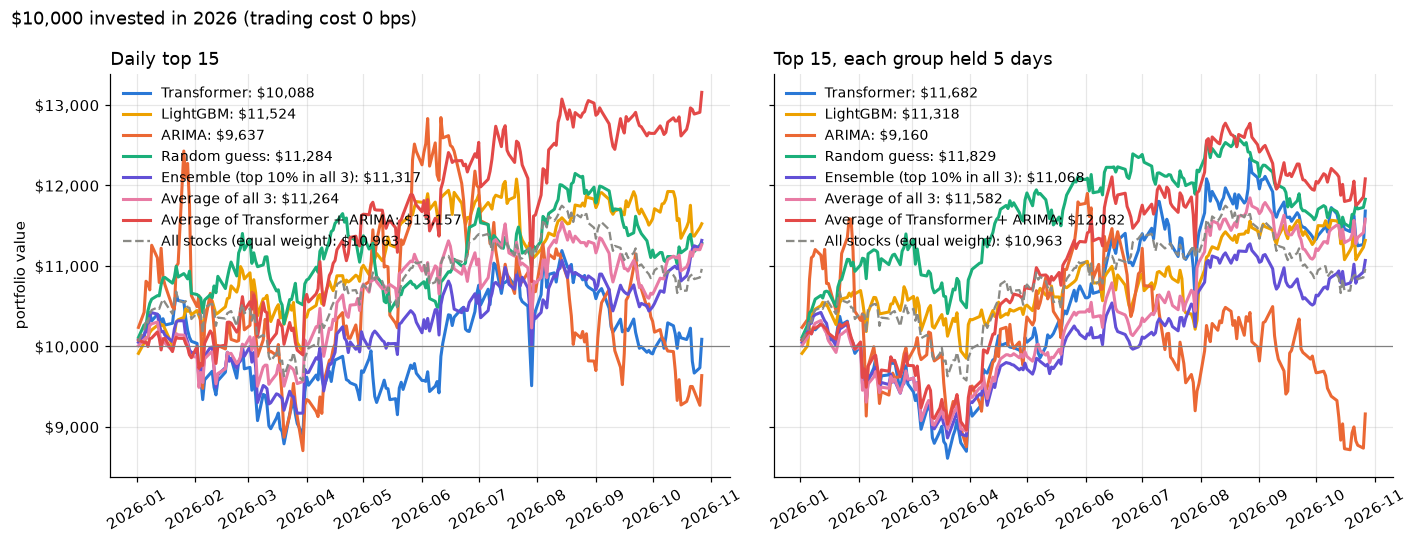

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (hold, r) in zip(axes, returns.items()):
    for name in r:
        growth = 10_000 * (1 + r[name]).cumprod()
        is_model = name != MARKET
        ax.plot(growth.index, growth, color=COLORS[name], lw=2 if is_model else 1.5, ls="-" if is_model else "--",
                label=f"{name}: ${growth.iloc[-1]:,.0f}")
    ax.axhline(10_000, color="gray", lw=0.8)
    ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
    ax.set_title(f"Daily top {TOP_N}" if hold == 1 else f"Top {TOP_N}, each group held {hold} days", loc="left")
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("portfolio value")
fig.suptitle(f"$10,000 invested in 2026 (trading cost {COST_BPS} bps)", x=0.01, ha="left")
fig.tight_layout()

## 3. Histogram of daily results (daily top 15)
Each bar counts the days on which the portfolio returned that much. The black line is the average day.
A useful strategy shifts the whole histogram to the right, not just a few lucky days.

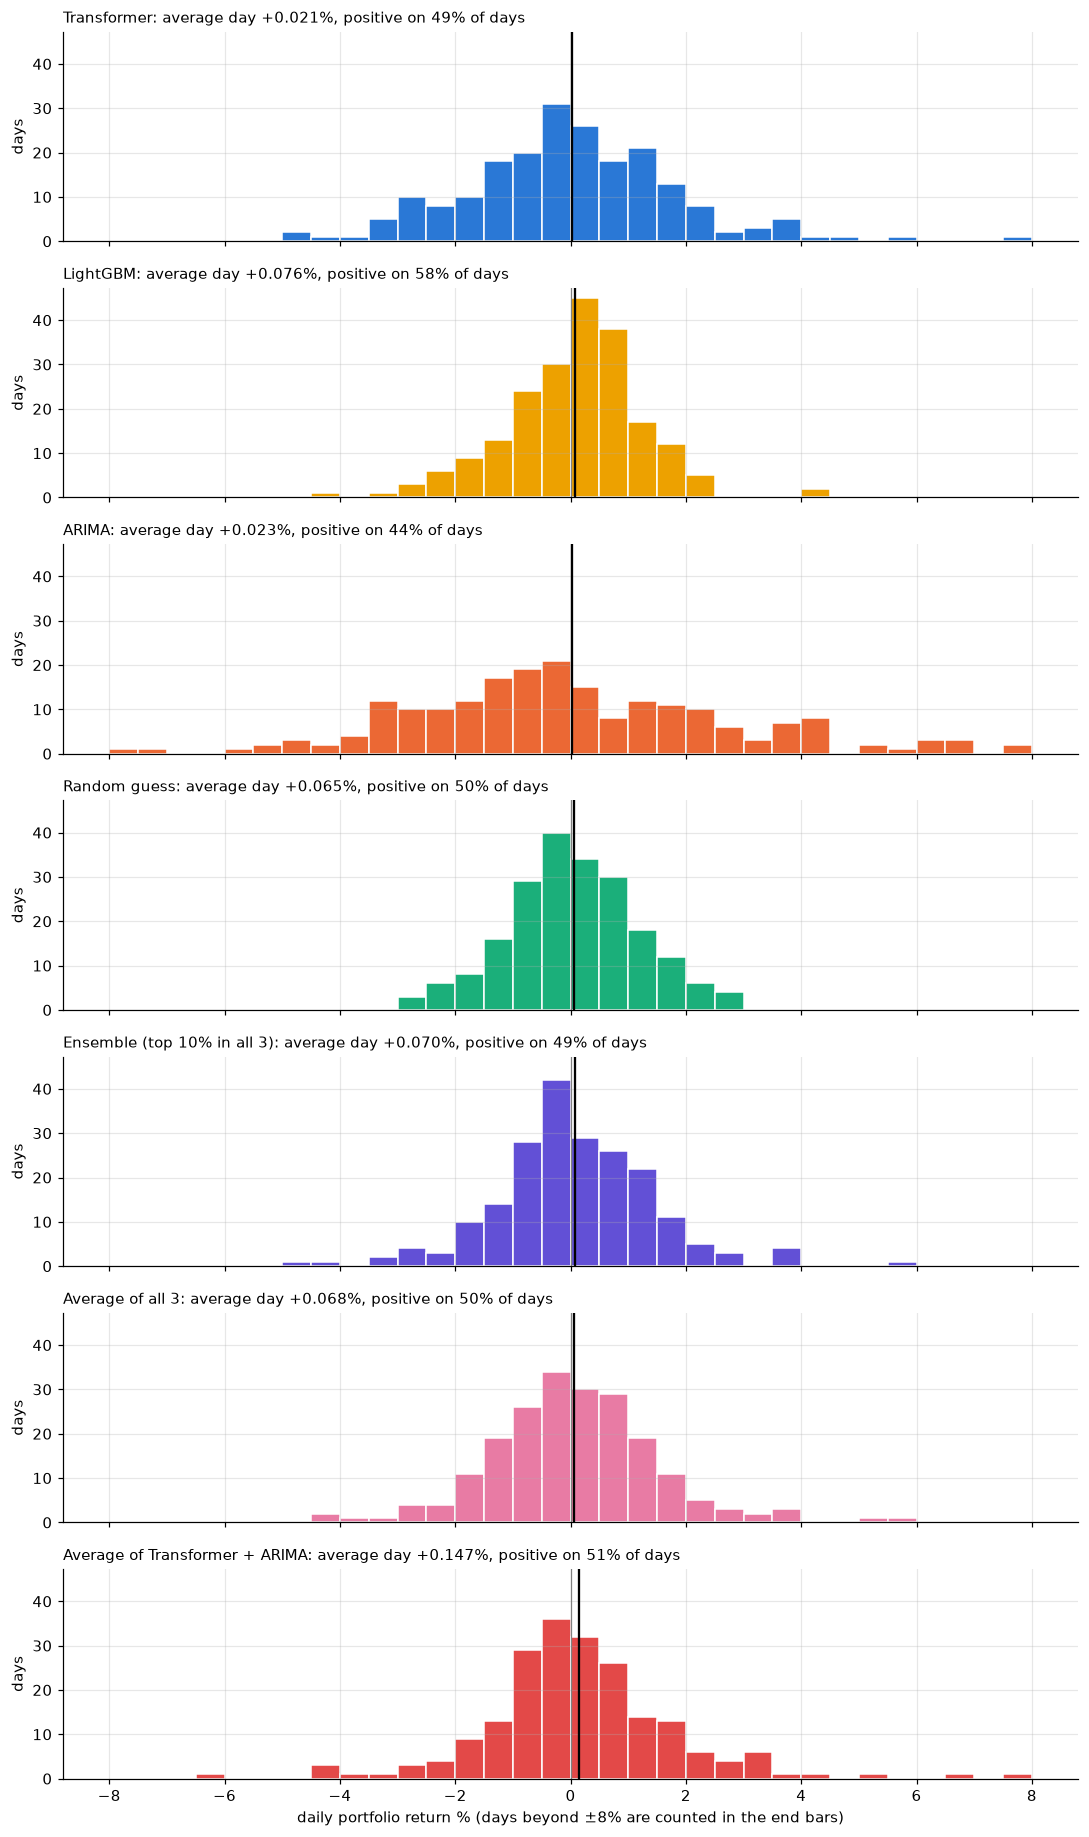

In [7]:
bins = np.arange(-8, 8.5, 0.5)
names = list(preds)
fig, axes = plt.subplots(len(names), 1, figsize=(10, 2.4 * len(names)), sharex=True, sharey=True)
for ax, name in zip(axes, names):
    r = returns[1][name]
    ax.hist(100 * r.clip(-0.08, 0.08), bins=bins, color=COLORS[name], edgecolor="white", linewidth=1)
    ax.axvline(0, color="gray", lw=0.8)
    ax.axvline(100 * r.mean(), color="black", lw=1.5)
    ax.set_title(f"{name}: average day {100 * r.mean():+.3f}%, positive on {100 * (r > 0).mean():.0f}% of days",
                 loc="left", fontsize=10)
    ax.set_ylabel("days")
axes[-1].set_xlabel("daily portfolio return % (days beyond ±8% are counted in the end bars)")
fig.tight_layout()

## 4. Is a model better than luck? Compare with 1,000 random portfolios (daily top 15)
The random strategy repeated 1,000 times (each day: 15 random tradable stocks). If a model really picks better stocks,
its result lands in the right tail. **"Random portfolios that did as well or better"** works like a p-value:
below 5% means the result is unlikely to be luck.

,total return %,random portfolios that did as well or better %
strategy,,
Transformer,0.876,71.300
LightGBM,15.243,29.700
ARIMA,-3.635,81.000
Ensemble (top 10% in all 3),13.174,35.600
Average of all 3,12.639,37.000
Average of Transformer + ARIMA,31.574,6.800
All stocks (equal weight),9.633,45.700


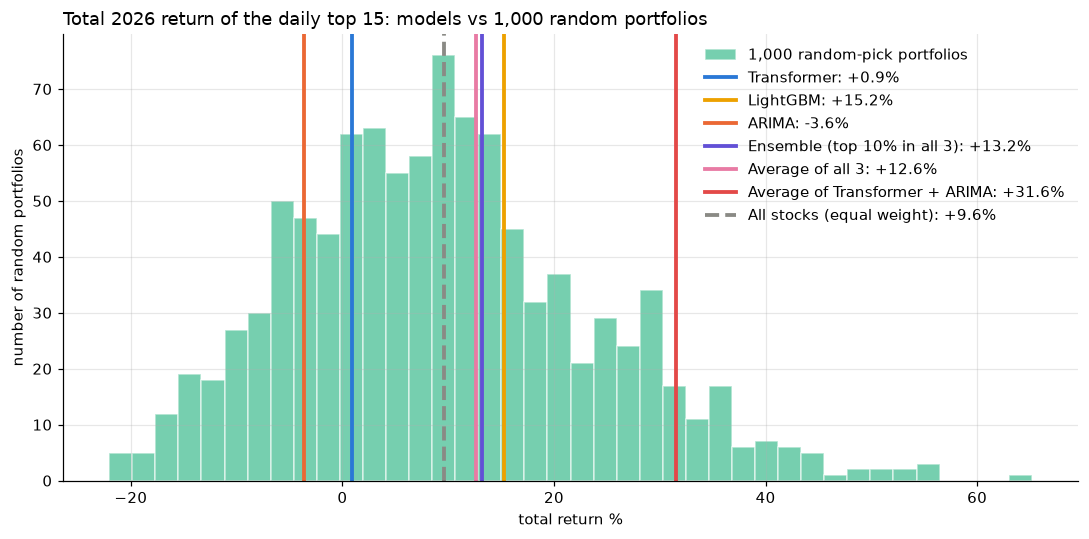

In [8]:
rng = np.random.default_rng(SEED)
day_returns = [g["ret"].to_numpy() for _, g in t[t["tradable"]].groupby("date")]
sim_daily = np.empty((N_RANDOM, len(day_returns)))
for j, r in enumerate(day_returns):
    pick = np.argpartition(rng.random((N_RANDOM, len(r))), TOP_N, axis=1)[:, :TOP_N]
    sim_daily[:, j] = r[pick].mean(axis=1) - 2 * COST_BPS / 1e4  # random picks replace nearly every name daily
sim_total = 100 * (np.prod(1 + sim_daily, axis=1) - 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(sim_total, bins=40, color=COLORS["Random guess"], alpha=0.6, edgecolor="white",
        label=f"{N_RANDOM:,} random-pick portfolios")
rows = []
for name in ["Transformer", "LightGBM", "ARIMA", ENSEMBLE, "Average of all 3", "Average of Transformer + ARIMA", MARKET]:
    total = 100 * ((1 + returns[1][name]).prod() - 1)
    ax.axvline(total, color=COLORS[name], lw=2.5, ls="--" if name == MARKET else "-", label=f"{name}: {total:+.1f}%")
    rows.append({"strategy": name, "total return %": total,
                 "random portfolios that did as well or better %": 100 * (sim_total >= total).mean()})
ax.set_title("Total 2026 return of the daily top 15: models vs 1,000 random portfolios", loc="left")
ax.set_xlabel("total return %")
ax.set_ylabel("number of random portfolios")
ax.legend(frameon=False)
fig.tight_layout()
pd.DataFrame(rows).set_index("strategy")

## 5. Are the strategies different? Day-by-day comparison
For each pair, take the difference in daily returns (A − B) on the same days and test whether its average is really above zero.
- **t-test p-value**: chance of a difference this large if the strategies were truly equal. Below 0.05 is the usual bar.
- **Wilcoxon p-value**: the same question based on ranks, so a few extreme days cannot dominate it.
- **95% range**: plausible values of the true average daily difference. If it includes 0, we cannot say they differ.

In [9]:
pairs = [("Transformer", "Random guess"), ("LightGBM", "Random guess"), ("ARIMA", "Random guess"),
         ("Transformer", "LightGBM"), ("Transformer", MARKET), ("LightGBM", MARKET),
         (ENSEMBLE, "Random guess"), (ENSEMBLE, "LightGBM"), (ENSEMBLE, MARKET),
         ("Average of all 3", "Random guess"), ("Average of all 3", "LightGBM"), ("Average of all 3", MARKET),
         ("Average of Transformer + ARIMA", "Random guess"), ("Average of Transformer + ARIMA", "LightGBM"), ("Average of Transformer + ARIMA", MARKET)]
rows = []
for hold, r in returns.items():
    for a, b in pairs:
        d = r[a] - r[b]
        se = d.std() / np.sqrt(len(d))
        rows.append({
            "strategy": f"daily top {TOP_N}" if hold == 1 else f"hold {hold} days",
            "A vs B": f"{a} vs {b}",
            "avg daily difference %": 100 * d.mean(),
            "95% range low %": 100 * (d.mean() - 1.96 * se),
            "95% range high %": 100 * (d.mean() + 1.96 * se),
            "A beat B on % of days": 100 * (d > 0).mean(),
            "t-test p-value": stats.ttest_1samp(d, 0).pvalue,
            "Wilcoxon p-value": stats.wilcoxon(d).pvalue,
        })
pd.DataFrame(rows).set_index(["strategy", "A vs B"]).style \
    .format("{:.3f}", subset=["t-test p-value", "Wilcoxon p-value"]) \
    .format("{:+.3f}", subset=["avg daily difference %", "95% range low %", "95% range high %"]) \
    .format("{:.0f}", subset=["A beat B on % of days"])

## 6. Average return by score decile
Each day, the tradable stocks are split into 10 equal groups by each model's score: decile 1 = the 10% the model likes least,
decile 10 = the 10% it likes most. The tables show each group's return **minus the average stock that day**
(this removes the whole market moving up or down), averaged over the test days, with a 95% margin of error.
`*` = the range excludes 0, i.e. clearly different from average. A model with real skill shows numbers rising from decile 1 to 10.

In [10]:
LABELS = [f"decile {d}" + (" (likes least)" if d == 1 else " (likes most)" if d == 10 else "") for d in range(1, 11)]


def decile_excess(df: pd.DataFrame, col: str) -> tuple[pd.Series, pd.Series]:
    pool = df[df["tradable"]].dropna(subset=[col]).copy()
    pool["decile"] = pool.groupby("date")["y_pred"].transform(
        lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    daily = pool.groupby(["date", "decile"])[col].mean().unstack()
    ex = 100 * daily.sub(pool.groupby("date")[col].mean(), axis=0)
    return ex.mean().set_axis(LABELS), (1.96 * ex.std() / np.sqrt(len(ex))).set_axis(LABELS)


decile_tables = {}
for col, title in [("ret", "next-day return"), ("ret_5d", f"next {HOLD_DAYS}-day return")]:
    mean, margin = {}, {}
    for name, df in preds.items():
        mean[name], margin[name] = decile_excess(df, col)
    mean, margin = pd.DataFrame(mean), pd.DataFrame(margin)
    decile_tables[title] = mean
    print(f"\n{title} % minus the average stock that day, ± 95% margin of error (* = range excludes 0)")
    display(mean.map(lambda v: f"{v:+.3f}") + " ± " + margin.map(lambda v: f"{v:.3f}")
            + np.where(mean.abs() > margin, " *", ""))


next-day return % minus the average stock that day, ± 95% margin of error (* = range excludes 0)


,Transformer,LightGBM,ARIMA,Random guess,Ensemble (top 10% in all 3),Average of all 3,Average of Transformer + ARIMA
decile 1 (likes least),-0.152 ± 0.199,-0.192 ± 0.210,-0.062 ± 0.091,-0.003 ± 0.030,-0.161 ± 0.184,-0.174 ± 0.157 *,-0.098 ± 0.130
decile 2,+0.001 ± 0.074,+0.002 ± 0.080,+0.021 ± 0.042,-0.017 ± 0.025,+0.006 ± 0.078,+0.011 ± 0.064,-0.057 ± 0.063
decile 3,+0.044 ± 0.040 *,+0.025 ± 0.044,+0.015 ± 0.034,-0.005 ± 0.029,+0.033 ± 0.042,+0.035 ± 0.052,+0.038 ± 0.035 *
decile 4,+0.010 ± 0.037,+0.028 ± 0.035,-0.043 ± 0.040 *,+0.028 ± 0.025 *,+0.022 ± 0.033,+0.001 ± 0.033,+0.004 ± 0.032
decile 5,+0.018 ± 0.043,+0.018 ± 0.040,-0.042 ± 0.036 *,+0.007 ± 0.026,+0.021 ± 0.033,+0.029 ± 0.032,+0.030 ± 0.031
decile 6,+0.010 ± 0.050,+0.014 ± 0.045,+0.006 ± 0.044,-0.008 ± 0.024,+0.014 ± 0.041,+0.014 ± 0.040,+0.016 ± 0.027
decile 7,+0.045 ± 0.050,+0.007 ± 0.054,+0.013 ± 0.041,-0.011 ± 0.024,+0.023 ± 0.046,+0.010 ± 0.045,+0.017 ± 0.038
decile 8,+0.008 ± 0.054,+0.025 ± 0.061,+0.007 ± 0.038,+0.003 ± 0.026,+0.004 ± 0.056,+0.027 ± 0.053,+0.003 ± 0.045
decile 9,+0.013 ± 0.060,+0.017 ± 0.064,+0.038 ± 0.038 *,-0.014 ± 0.025,+0.020 ± 0.062,+0.019 ± 0.062,+0.028 ± 0.056
decile 10 (likes most),+0.004 ± 0.086,+0.057 ± 0.067,+0.045 ± 0.083,+0.019 ± 0.026,+0.018 ± 0.072,+0.029 ± 0.073,+0.019 ± 0.071



next 5-day return % minus the average stock that day, ± 95% margin of error (* = range excludes 0)


,Transformer,LightGBM,ARIMA,Random guess,Ensemble (top 10% in all 3),Average of all 3,Average of Transformer + ARIMA
decile 1 (likes least),-0.784 ± 0.461 *,-0.917 ± 0.485 *,-0.339 ± 0.234 *,-0.014 ± 0.061,-0.848 ± 0.427 *,-0.792 ± 0.375 *,-0.432 ± 0.316 *
decile 2,+0.061 ± 0.191,+0.017 ± 0.216,+0.044 ± 0.082,+0.024 ± 0.058,+0.003 ± 0.193,+0.054 ± 0.153,-0.286 ± 0.137 *
decile 3,+0.167 ± 0.089 *,+0.141 ± 0.095 *,+0.076 ± 0.072 *,-0.064 ± 0.060 *,+0.131 ± 0.105 *,+0.070 ± 0.127,+0.156 ± 0.076 *
decile 4,+0.085 ± 0.088,+0.119 ± 0.084 *,-0.176 ± 0.092 *,+0.045 ± 0.060,+0.132 ± 0.074 *,+0.092 ± 0.074 *,+0.061 ± 0.064
decile 5,+0.107 ± 0.093 *,+0.122 ± 0.101 *,-0.131 ± 0.093 *,+0.010 ± 0.065,+0.135 ± 0.087 *,+0.087 ± 0.076 *,+0.093 ± 0.080 *
decile 6,+0.123 ± 0.106 *,+0.103 ± 0.114,+0.062 ± 0.091,-0.056 ± 0.058,+0.080 ± 0.101,+0.108 ± 0.090 *,+0.061 ± 0.060 *
decile 7,+0.163 ± 0.116 *,+0.113 ± 0.127,+0.064 ± 0.090,-0.003 ± 0.062,+0.092 ± 0.111,+0.122 ± 0.111 *,+0.092 ± 0.093
decile 8,+0.092 ± 0.125,+0.101 ± 0.139,+0.069 ± 0.085,-0.016 ± 0.055,+0.078 ± 0.132,+0.064 ± 0.126,+0.075 ± 0.108
decile 9,+0.028 ± 0.140,+0.112 ± 0.151,+0.140 ± 0.084 *,+0.040 ± 0.056,+0.102 ± 0.147,+0.096 ± 0.144,+0.084 ± 0.132
decile 10 (likes most),-0.038 ± 0.181,+0.092 ± 0.166,+0.191 ± 0.168 *,+0.035 ± 0.059,+0.096 ± 0.167,+0.100 ± 0.175,+0.096 ± 0.159


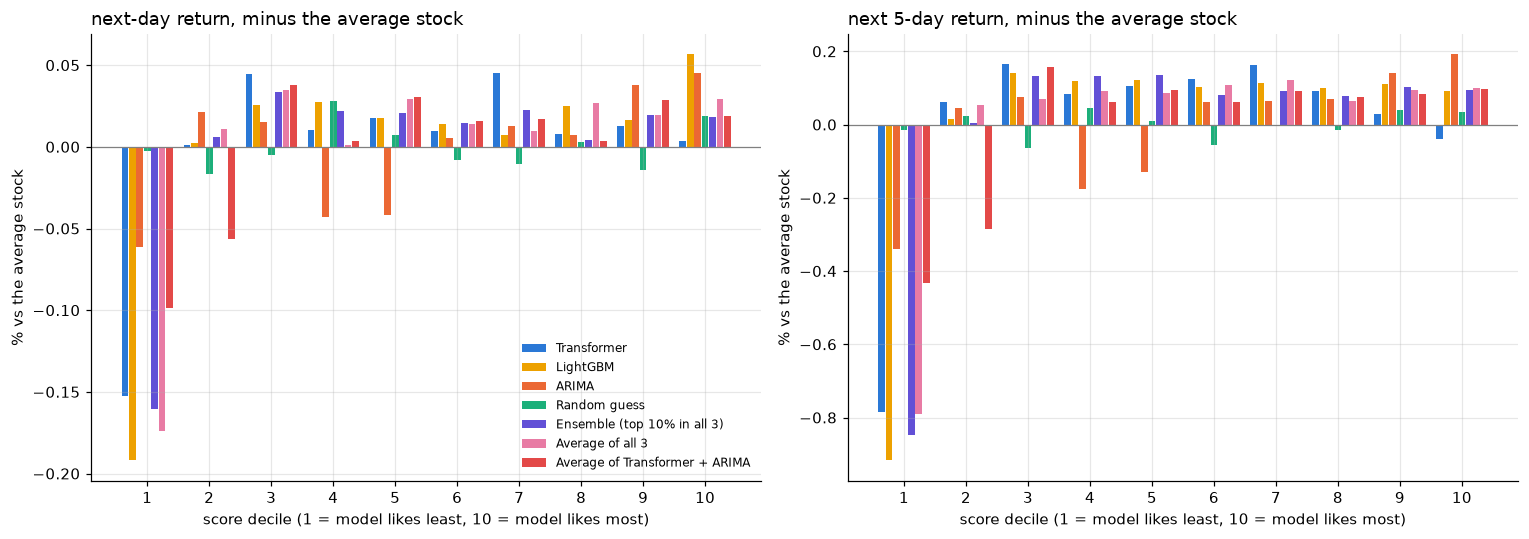

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(1, 11)
width = 0.12
for ax, (title, table) in zip(axes, decile_tables.items()):
    for k, name in enumerate(preds):
        ax.bar(x + (k - 3) * width, table[name], width=width * 0.9, color=COLORS[name], label=name)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xticks(x, [str(d) for d in x])
    ax.set_xlabel("score decile (1 = model likes least, 10 = model likes most)")
    ax.set_ylabel("% vs the average stock")
    ax.set_title(f"{title}, minus the average stock", loc="left")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## 7. Sanity check: the most extreme trades
Single-stock moves above +50% or below −50% among the stocks each strategy bought (daily top 15). A few real ones are normal
(trial results, takeovers); a stock jumping up and straight back down is more likely a data error.

In [12]:
picks = pd.concat([pick_top(df).assign(strategy=name) for name, df in preds.items()])
picks["return %"] = 100 * picks["ret"]
extreme = picks[picks["return %"].abs() > 50][["strategy", "date", "ticker", "return %"]]
print(f"{len(extreme)} extreme trades out of {len(picks):,} stock-days held")
extreme.sort_values("return %")

9 extreme trades out of 21,630 stock-days held


,strategy,date,ticker,return %
82702,ARIMA,2026-01-30,KXIN,-88.154
760994,ARIMA,2026-09-17,BIAF,63.551
521146,ARIMA,2026-06-29,SDOT,67.133
756206,ARIMA,2026-09-16,AEHL,78.682
425860,ARIMA,2026-05-27,QTTB,81.241
8653,ARIMA,2026-01-06,ALMS,95.307
24532,ARIMA,2026-01-09,SDEV,102.537
170319,ARIMA,2026-03-03,BATL,134.576
64135,ARIMA,2026-01-26,BNAI,276.699


## 8. Top 10% instead of top 15: next 5-day return
15 stocks out of ~2,600 is a tiny sample, so a few big movers decide the result. Here each model's **top 10%**
(about 260 stocks per day) is used instead, matching the models' 5-day target.

**A. How did the top 10% do over the next 5 days?** For every day, the average 5-day return of the model's top 10%,
minus the average tradable stock over the same 5 days. Consecutive days share 4 of their 5 days, so the
significance test uses only every 5th day (non-overlapping periods) to avoid overstating confidence.

In [13]:
TOP_FRAC = 0.10


def pick_top_frac(df: pd.DataFrame, name: str, frac: float = TOP_FRAC) -> pd.DataFrame:
    # the top `frac` of tradable stocks by score, for every day;
    # for the ensemble: the stocks in the top `frac` of all three models
    pool = df[df["tradable"]]
    if name == ENSEMBLE:
        return pool[pool["y_pred"] > 1 - frac]
    return pool[pool.groupby("date")["y_pred"].rank(pct=True, ascending=False) <= frac]


rows = []
for name, df in preds.items():
    pool = df[df["tradable"]].dropna(subset=["ret_5d"])
    top = pick_top_frac(pool, name).groupby("date")["ret_5d"].mean()
    avg = pool.groupby("date")["ret_5d"].mean()
    excess = 100 * (top - avg)
    sample = excess.iloc[::HOLD_DAYS]  # non-overlapping 5-day periods
    rows.append({
        "model": name,
        "top 10% avg 5-day return %": 100 * top.mean(),
        "average stock 5-day return %": 100 * avg.mean(),
        "top 10% minus average %": excess.mean(),
        "95% margin ±": 1.96 * sample.std() / np.sqrt(len(sample)),
        "top 10% beat average on % of days": 100 * (excess > 0).mean(),
        "p-value (t-test, non-overlapping)": stats.ttest_1samp(sample, 0).pvalue,
    })
print(f"{len(sample)} non-overlapping 5-day periods in the test")
pd.DataFrame(rows).set_index("model").style.format("{:+.3f}", subset=["top 10% avg 5-day return %",
    "average stock 5-day return %", "top 10% minus average %"]).format("{:.3f}", subset=["95% margin ±",
    "p-value (t-test, non-overlapping)"]).format("{:.0f}", subset=["top 10% beat average on % of days"])

41 non-overlapping 5-day periods in the test


,top 10% avg 5-day return %,average stock 5-day return %,top 10% minus average %,95% margin ±,top 10% beat average on % of days,"p-value (t-test, non-overlapping)"
model,,,,,,
Transformer,+0.148,+0.188,-0.040,0.360,45,0.904
LightGBM,+0.281,+0.188,+0.093,0.349,54,0.425
ARIMA,+0.378,+0.188,+0.190,0.403,58,0.115
Random guess,+0.223,+0.188,+0.035,0.099,51,0.159
Ensemble (top 10% in all 3),+0.232,+0.188,+0.044,0.630,53,0.437
Average of all 3,+0.288,+0.188,+0.100,0.327,53,0.220
Average of Transformer + ARIMA,+0.283,+0.188,+0.095,0.324,50,0.210


**B. Backtest: top 10%, held 5 days.** Each day 1/5 of the money buys that day's top 10% (equal weight) and holds it
5 days, so the portfolio always holds 5 overlapping groups (about 1,300 positions, many of them the same stocks).
Trading cost 0.

In [14]:
def backtest_groups(groups: pd.Series, hold: int = HOLD_DAYS) -> pd.Series:
    # daily return when each day's group of stocks is held `hold` days with 1/hold of the money
    dates = ret_wide.index
    daily = [np.mean([ret_wide.loc[day, groups[dates[i - k]]].mean()
                      for k in range(hold) if i - k >= 0 and dates[i - k] in groups.index])
             for i, day in enumerate(dates)]
    return pd.Series(daily, index=pd.to_datetime(dates))


top10 = pd.DataFrame({name: backtest_groups(pick_top_frac(df, name).groupby("date")["ticker"].apply(list))
                      for name, df in preds.items()})
top10[MARKET] = market
pd.DataFrame({n: summary_stats(top10[n]) for n in top10}).T.style.format("{:,.2f}")

,"$10,000 becomes",total return %,annualized return %,annualized volatility %,Sharpe ratio,max drawdown %,winning days %,average day %,best day %,worst day %
Transformer,"10,789.11",7.89,9.74,15.69,0.67,-14.01,51.46,0.04,3.49,-2.75
LightGBM,"11,413.61",14.14,17.56,13.46,1.27,-9.53,54.85,0.07,3.04,-2.43
ARIMA,"11,999.54",20.00,24.98,19.98,1.22,-10.86,51.94,0.10,4.53,-3.54
Random guess,"11,123.49",11.23,13.91,15.47,0.92,-9.61,53.40,0.06,3.07,-2.30
Ensemble (top 10% in all 3),"11,157.23",11.57,14.33,17.88,0.84,-14.33,51.94,0.06,3.66,-5.32
Average of all 3,"11,442.50",14.43,17.92,13.73,1.27,-9.76,53.88,0.07,2.95,-2.30
Average of Transformer + ARIMA,"11,430.43",14.30,17.77,14.52,1.20,-10.41,55.83,0.07,3.08,-2.43
All stocks (equal weight),"10,963.30",9.63,11.91,15.50,0.80,-10.34,55.34,0.05,3.08,-2.39


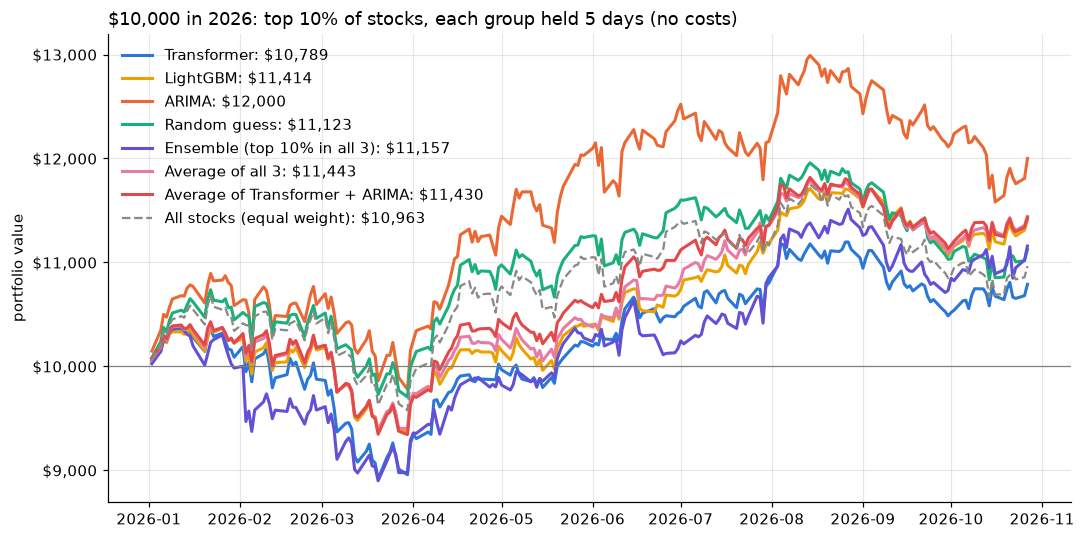

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in top10:
    growth = 10_000 * (1 + top10[name]).cumprod()
    is_model = name != MARKET
    ax.plot(growth.index, growth, color=COLORS[name], lw=2 if is_model else 1.5, ls="-" if is_model else "--",
            label=f"{name}: ${growth.iloc[-1]:,.0f}")
ax.axhline(10_000, color="gray", lw=0.8)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.set_title(f"$10,000 in 2026: top 10% of stocks, each group held {HOLD_DAYS} days (no costs)", loc="left")
ax.set_ylabel("portfolio value")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()

In [16]:
rows = []
for a, b in [("Transformer", "Random guess"), ("LightGBM", "Random guess"), ("ARIMA", "Random guess"),
             ("Transformer", "LightGBM"), ("Transformer", MARKET), ("LightGBM", MARKET), ("ARIMA", MARKET),
             (ENSEMBLE, "Random guess"), (ENSEMBLE, "LightGBM"), (ENSEMBLE, MARKET),
         ("Average of all 3", "Random guess"), ("Average of all 3", "LightGBM"), ("Average of all 3", MARKET),
         ("Average of Transformer + ARIMA", "Random guess"), ("Average of Transformer + ARIMA", "LightGBM"), ("Average of Transformer + ARIMA", MARKET)]:
    d = top10[a] - top10[b]
    se = d.std() / np.sqrt(len(d))
    rows.append({"A vs B": f"{a} vs {b}", "avg daily difference %": 100 * d.mean(),
                 "95% range low %": 100 * (d.mean() - 1.96 * se), "95% range high %": 100 * (d.mean() + 1.96 * se),
                 "difference over the whole period %": 100 * ((1 + top10[a]).prod() - (1 + top10[b]).prod()),
                 "A beat B on % of days": 100 * (d > 0).mean(),
                 "t-test p-value": stats.ttest_1samp(d, 0).pvalue, "Wilcoxon p-value": stats.wilcoxon(d).pvalue})
pd.DataFrame(rows).set_index("A vs B").style \
    .format("{:.3f}", subset=["t-test p-value", "Wilcoxon p-value"]) \
    .format("{:+.3f}", subset=["avg daily difference %", "95% range low %", "95% range high %"]) \
    .format("{:+.1f}", subset=["difference over the whole period %"]) \
    .format("{:.0f}", subset=["A beat B on % of days"])

,avg daily difference %,95% range low %,95% range high %,difference over the whole period %,A beat B on % of days,t-test p-value,Wilcoxon p-value
A vs B,,,,,,,
Transformer vs Random guess,-0.015,-0.089,+0.060,-3.3,49,0.699,0.634
LightGBM vs Random guess,+0.011,-0.054,+0.076,+2.9,50,0.732,0.879
ARIMA vs Random guess,+0.040,-0.023,+0.103,+8.8,57,0.218,0.096
Transformer vs LightGBM,-0.026,-0.082,+0.030,-6.2,49,0.366,0.422
Transformer vs All stocks (equal weight),-0.008,-0.083,+0.067,-1.7,50,0.842,0.779
LightGBM vs All stocks (equal weight),+0.018,-0.048,+0.085,+4.5,50,0.590,0.721
ARIMA vs All stocks (equal weight),+0.047,-0.014,+0.108,+10.4,60,0.135,0.048
Ensemble (top 10% in all 3) vs Random guess,+0.003,-0.108,+0.114,+0.3,52,0.957,0.670
Ensemble (top 10% in all 3) vs LightGBM,-0.008,-0.092,+0.075,-2.6,53,0.847,0.783


## 9. Use the signal where it is: the bottom 10%
Section 6 showed that the models are best at spotting the stocks that will **lag** over the next 5 days (decile 1),
not the ones that will lead. Three ways to use that, all held 5 days (each day 1/5 of the money, like section 8B), no costs:
- **A. All stocks minus the bottom 10%** (long only): buy every tradable stock except the 10% the model likes least.
  Compared with **All stocks (held 5 days)**, the same construction without removing anything.
- **B. Long top 10%, short bottom 10%**: \$1 long the top 10% and \$1 short the bottom 10%. Makes money when the top
  group beats the bottom group, whatever the market does.
- **C. Long all stocks, short bottom 10%**: \$1 long all stocks, \$1 short the bottom 10%. The purest test of the
  "spot the losers" skill: it earns the gap between the average stock and the bottom group.

B and C need short selling, which in reality costs a borrow fee (often 0.3–5% a year, much more for hard-to-borrow
small stocks) and is not always possible. Ignored here. The "Ensemble (top 10% in all 3)" is left out: its score is built
for picking the top, not the bottom.

**First, how did the bottom 10% do?** Same layout as 8A: the bottom 10%'s average 5-day return minus the average stock,
tested on non-overlapping 5-day periods.

In [17]:
MODELS_9 = [n for n in preds if n != ENSEMBLE]


def pick_bottom_frac(df: pd.DataFrame, frac: float = TOP_FRAC) -> pd.DataFrame:
    # the `frac` of tradable stocks with the lowest score, for every day
    pool = df[df["tradable"]]
    return pool[pool.groupby("date")["y_pred"].rank(pct=True, method="first") <= frac]


rows = []
for name in MODELS_9:
    pool = preds[name][preds[name]["tradable"]].dropna(subset=["ret_5d"])
    bottom = pick_bottom_frac(pool).groupby("date")["ret_5d"].mean()
    avg = pool.groupby("date")["ret_5d"].mean()
    excess = 100 * (bottom - avg)
    sample = excess.iloc[::HOLD_DAYS]  # non-overlapping 5-day periods
    rows.append({
        "model": name,
        "bottom 10% avg 5-day return %": 100 * bottom.mean(),
        "average stock 5-day return %": 100 * avg.mean(),
        "bottom 10% minus average %": excess.mean(),
        "95% margin ±": 1.96 * sample.std() / np.sqrt(len(sample)),
        "bottom 10% lagged average on % of days": 100 * (excess < 0).mean(),
        "p-value (t-test, non-overlapping)": stats.ttest_1samp(sample, 0).pvalue,
    })
pd.DataFrame(rows).set_index("model").style.format("{:+.3f}", subset=["bottom 10% avg 5-day return %",
    "average stock 5-day return %", "bottom 10% minus average %"]).format("{:.3f}", subset=["95% margin ±",
    "p-value (t-test, non-overlapping)"]).format("{:.0f}", subset=["bottom 10% lagged average on % of days"])

,bottom 10% avg 5-day return %,average stock 5-day return %,bottom 10% minus average %,95% margin ±,bottom 10% lagged average on % of days,"p-value (t-test, non-overlapping)"
model,,,,,,
Transformer,-0.601,+0.188,-0.789,1.001,56,0.128
LightGBM,-0.732,+0.188,-0.921,1.064,54,0.090
ARIMA,-0.150,+0.188,-0.338,0.531,56,0.176
Random guess,+0.175,+0.188,-0.013,0.154,53,0.702
Average of all 3,-0.602,+0.188,-0.790,0.797,57,0.050
Average of Transformer + ARIMA,-0.244,+0.188,-0.433,0.704,55,0.278


**The three strategies.** \$10,000 at the start of 2026. For A, the key number is how far it gets ahead of
*All stocks (held 5 days)*; for B and C, any profit at all is the model's skill, since the market's moves cancel out.

In [18]:
ALL_HELD = f"All stocks (held {HOLD_DAYS} days)"
STRATEGIES_9 = {"A": "A. All stocks minus bottom 10%", "B": "B. Long top 10%, short bottom 10%",
                "C": "C. Long all stocks, short bottom 10%"}
as_groups = lambda df: df.groupby("date")["ticker"].apply(list)

all_held = backtest_groups(as_groups(t[t["tradable"]]))
strat9 = {key: {} for key in STRATEGIES_9}
for name in MODELS_9:
    pool = preds[name][preds[name]["tradable"]]
    bottom = pick_bottom_frac(pool)
    bottom_r = backtest_groups(as_groups(bottom))
    strat9["A"][name] = backtest_groups(as_groups(pool.drop(bottom.index)))
    strat9["B"][name] = top10[name] - bottom_r
    strat9["C"][name] = all_held - bottom_r
strat9 = {key: pd.DataFrame(r) for key, r in strat9.items()}
strat9["A"][ALL_HELD] = all_held

pd.concat({STRATEGIES_9[key]: pd.DataFrame({n: summary_stats(r[n]) for n in r}).T for key, r in strat9.items()}) \
    .style.format("{:,.2f}")

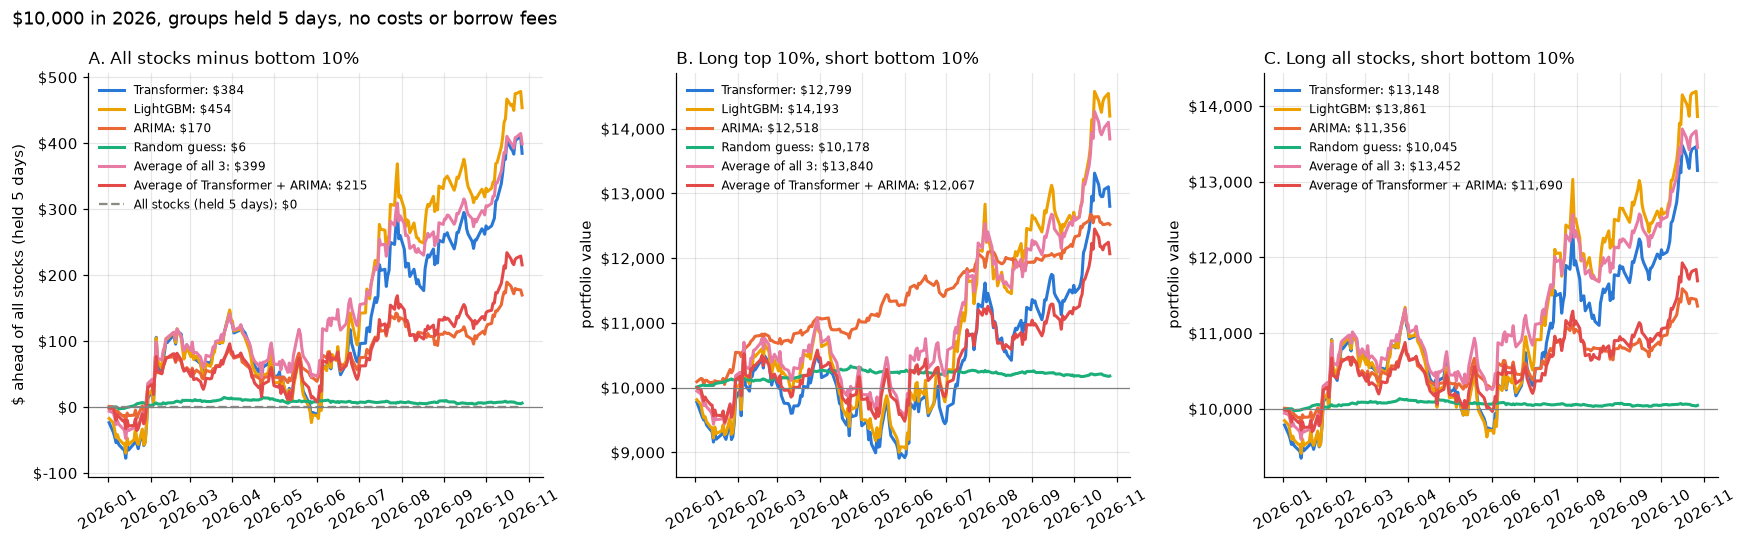

In [19]:
COLORS[ALL_HELD] = COLORS[MARKET]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (key, r) in zip(axes, strat9.items()):
    for name in r:
        growth = 10_000 * (1 + r[name]).cumprod()
        if key == "A":  # dollars ahead of (or behind) all stocks
            growth = growth - 10_000 * (1 + r[ALL_HELD]).cumprod()
        is_model = name != ALL_HELD
        ax.plot(growth.index, growth, color=COLORS[name], lw=2 if is_model else 1.5, ls="-" if is_model else "--",
                label=f"{name}: ${growth.iloc[-1]:,.0f}")
    ax.axhline(0 if key == "A" else 10_000, color="gray", lw=0.8)
    ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
    ax.set_title(STRATEGIES_9[key], loc="left", fontsize=11)
    ax.set_ylabel("$ ahead of all stocks (held 5 days)" if key == "A" else "portfolio value")
    ax.legend(loc="upper left", frameon=False, fontsize=8)
    ax.tick_params(axis="x", labelrotation=30)
fig.suptitle("$10,000 in 2026, groups held 5 days, no costs or borrow fees", x=0.01, ha="left")
fig.tight_layout()

**Is it more than luck?** A: daily return minus *All stocks (held 5 days)*. B and C: the daily return itself
(they hold no market exposure, so 0 is the no-skill line). Random guess is the control: it should show nothing.
Consecutive days share stocks, so treat p-values near 0.05 as weak evidence.

In [20]:
rows = []
for key, r in strat9.items():
    for name in MODELS_9:
        d = r[name] - r[ALL_HELD] if key == "A" else r[name]
        se = d.std() / np.sqrt(len(d))
        rows.append({"strategy": STRATEGIES_9[key], "model": name,
                     "avg daily gain %": 100 * d.mean(),
                     "95% range low %": 100 * (d.mean() - 1.96 * se), "95% range high %": 100 * (d.mean() + 1.96 * se),
                     "gain over the whole period %": 100 * ((1 + r[name]).prod() - (
                         (1 + r[ALL_HELD]).prod() if key == "A" else 1)),
                     "positive on % of days": 100 * (d > 0).mean(),
                     "t-test p-value": stats.ttest_1samp(d, 0).pvalue, "Wilcoxon p-value": stats.wilcoxon(d).pvalue})
pd.DataFrame(rows).set_index(["strategy", "model"]).style \
    .format("{:.3f}", subset=["t-test p-value", "Wilcoxon p-value"]) \
    .format("{:+.3f}", subset=["avg daily gain %", "95% range low %", "95% range high %"]) \
    .format("{:+.1f}", subset=["gain over the whole period %"]) \
    .format("{:.0f}", subset=["positive on % of days"])

## Caveats
- **One period.** About 200 trading days in a single year. A strategy that wins here can lose in another year.
- **2026 has been looked at before.** Earlier versions were evaluated on the same period, so it is not a perfectly clean test any more. Paper trading from November 2026 is the cleanest next check.
- **Survivorship bias.** Only stocks that still exist in late 2026 are included, which flatters every strategy, including the market line.
- **Costs and execution.** Costs are zero here, and trades happen exactly at the close. Set `COST_BPS` to 5–10 to see a more realistic picture: the daily top-15 strategy replaces most of its stocks every day.
- **Short selling (section 9 B and C).** Borrow fees, stocks that cannot be borrowed and the risk of a short squeeze are all ignored, and they hit exactly the kind of weak small stocks the bottom 10% holds.